# 🛒 Segmentation client RFM - Online Retail

**Objectif :** segmenter la base clients d'un e-commerçant britannique avec la méthode **RFM** (Récence, Fréquence, Montant), afin de définir des actions marketing adaptées à chaque groupe de clients.

**Données :** [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail), UCI Machine Learning Repository : environ 540 000 lignes de transactions entre décembre 2010 et décembre 2011.

**Plan :**
1. Chargement et nettoyage des données
2. Calcul des indicateurs RFM par client
3. Scores de 1 à 5 par quintiles
4. Segmentation en 10 segments
5. Analyse des segments et recommandations marketing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
OUTPUT = "output/"


## 1. Chargement et nettoyage

In [2]:
df = pd.read_excel("data/Online Retail.xlsx", dtype={"CustomerID": "Int64", "InvoiceNo": str, "StockCode": str})
print(f"{len(df):,} lignes, {df['CustomerID'].nunique():,} clients identifiés")
df.head()

541,909 lignes, 4,372 clients identifiés


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [3]:
avant = len(df)
df = df.dropna(subset=["CustomerID"])                          # clients non identifiés
df = df[~df["InvoiceNo"].str.startswith("C")]                  # factures annulées
df = df[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)]          # quantités et prix invalides
df = df.drop_duplicates()
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]

print(f"Lignes supprimées au nettoyage : {avant - len(df):,} ({(avant - len(df)) / avant:.1%})")
print(f"Données propres : {len(df):,} lignes, {df['CustomerID'].nunique():,} clients, "
      f"{df['InvoiceNo'].nunique():,} commandes, CA = {df['TotalPrice'].sum():,.0f} £")

Lignes supprimées au nettoyage : 149,217 (27.5%)
Données propres : 392,692 lignes, 4,338 clients, 18,532 commandes, CA = 8,887,209 £


## 2. Calcul des indicateurs RFM

La date de référence est le lendemain de la dernière transaction.

In [4]:
date_ref = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recence=("InvoiceDate", lambda d: (date_ref - d.max()).days),
    Frequence=("InvoiceNo", "nunique"),
    Montant=("TotalPrice", "sum"),
)
rfm.describe().round(1)

,Recence,Frequence,Montant
count,4338.0,4338.0,4338.0
mean,92.5,4.3,2048.7
std,100.0,7.7,8985.2
min,1.0,1.0,3.8
25%,18.0,1.0,306.5
50%,51.0,2.0,668.6
75%,142.0,5.0,1660.6
max,374.0,209.0,280206.0


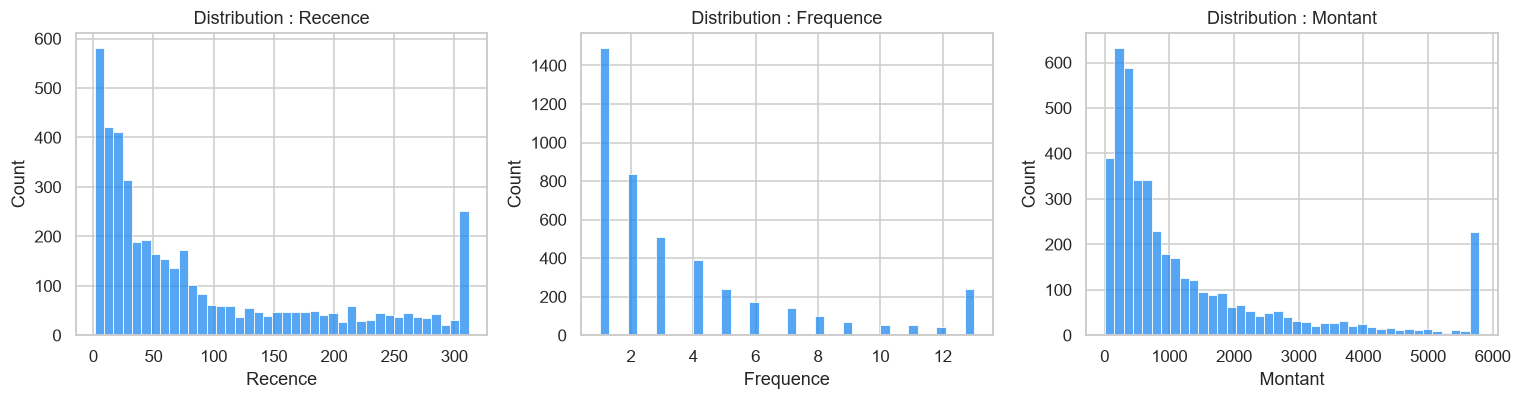

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col in zip(axes, ["Recence", "Frequence", "Montant"]):
    data = rfm[col].clip(upper=rfm[col].quantile(0.95))  # on coupe les 5 % extrêmes pour la lisibilité
    sns.histplot(data, bins=40, ax=ax, color="#1e88f0")
    ax.set_title(f"Distribution : {col}")
plt.tight_layout()
plt.savefig(OUTPUT + "distributions_rfm.png", bbox_inches="tight")
plt.show()

## 3. Scores de 1 à 5

Chaque indicateur est découpé en quintiles. Pour la récence, un faible nombre de jours donne le meilleur score (5).

In [6]:
rfm["R"] = pd.qcut(rfm["Recence"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
# rank() évite les quintiles en doublon (beaucoup de clients n'ont qu'une commande)
rfm["F"] = pd.qcut(rfm["Frequence"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Montant"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RF"] = rfm["R"].astype(str) + rfm["F"].astype(str)
rfm.head()

,Recence,Frequence,Montant,R,F,M,RF
CustomerID,,,,,,,
12346,326,1,77183.60,1,1,5,11
12347,2,7,4310.00,5,5,5,55
12348,75,4,1797.24,2,4,4,24
12349,19,1,1757.55,4,1,4,41
12350,310,1,334.40,1,1,2,11


## 4. Segmentation

Les segments sont définis à partir des scores de récence et de fréquence (grille RFM classique).

In [7]:
segments = {
    r"[1-2][1-2]": "Hibernating",
    r"[1-2][3-4]": "At Risk",
    r"[1-2]5": "Can't Lose Them",
    r"3[1-2]": "About to Sleep",
    r"33": "Need Attention",
    r"[3-4][4-5]": "Loyal Customers",
    r"41": "Promising",
    r"51": "New Customers",
    r"[4-5][2-3]": "Potential Loyalists",
    r"5[4-5]": "Champions",
}
rfm["Segment"] = rfm["RF"].replace(segments, regex=True)

resume = rfm.groupby("Segment").agg(
    Clients=("Recence", "size"),
    Recence_moy=("Recence", "mean"),
    Frequence_moy=("Frequence", "mean"),
    Montant_moy=("Montant", "mean"),
    CA=("Montant", "sum"),
)
resume["% clients"] = resume["Clients"] / resume["Clients"].sum() * 100
resume["% CA"] = resume["CA"] / resume["CA"].sum() * 100
resume = resume.sort_values("CA", ascending=False)
resume.round(1)

,Clients,Recence_moy,Frequence_moy,Montant_moy,CA,% clients,% CA
Segment,,,,,,,
Champions,633,5.9,12.4,6843.2,4331720.6,14.6,48.7
Loyal Customers,827,33.5,6.5,2848.3,2355571.7,19.1,26.5
At Risk,580,155.1,2.9,1072.9,622276.1,13.4,7.0
Hibernating,1065,217.9,1.1,486.7,518322.2,24.6,5.8
Potential Loyalists,492,17.1,2.0,1030.1,506813.6,11.3,5.7
Can't Lose Them,63,132.4,8.4,2790.1,175776.4,1.5,2.0
Need Attention,186,53.1,2.3,884.2,164468.6,4.3,1.9
About to Sleep,351,53.5,1.2,459.0,161108.1,8.1,1.8
Promising,99,23.4,1.0,353.3,34980.7,2.3,0.4


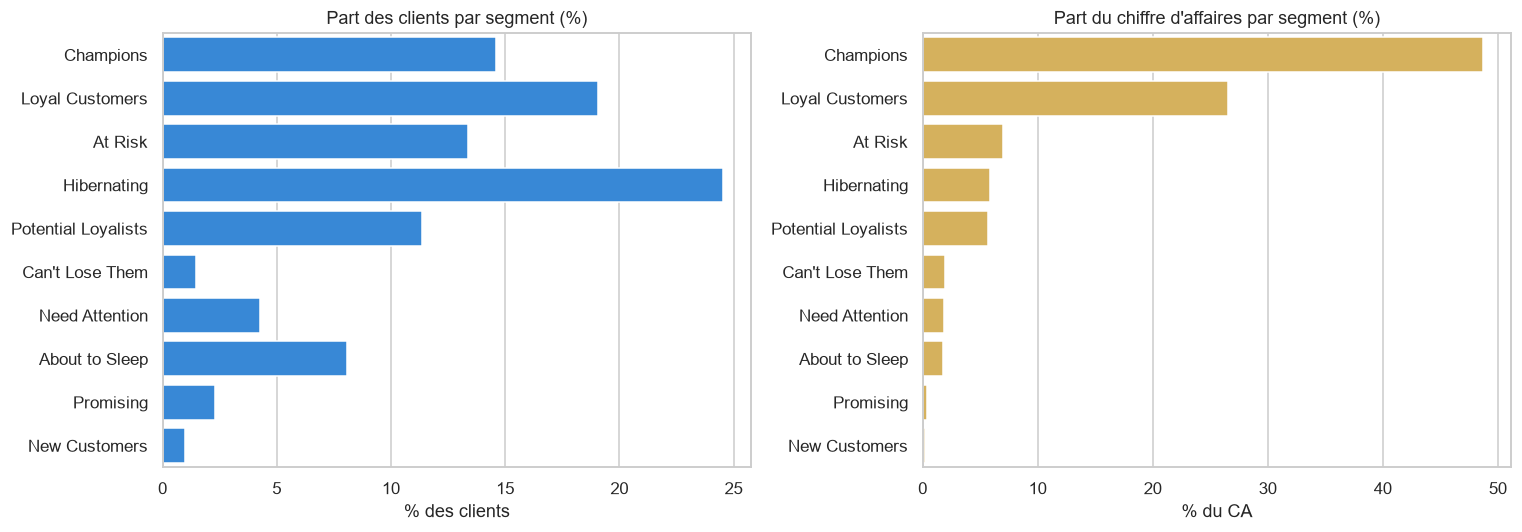

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ordre = resume.index

sns.barplot(x=resume["% clients"], y=ordre, ax=axes[0], color="#1e88f0")
axes[0].set_title("Part des clients par segment (%)")
axes[0].set_xlabel("% des clients"); axes[0].set_ylabel("")

sns.barplot(x=resume["% CA"], y=ordre, ax=axes[1], color="#e9b949")
axes[1].set_title("Part du chiffre d'affaires par segment (%)")
axes[1].set_xlabel("% du CA"); axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(OUTPUT + "segments_clients_ca.png", bbox_inches="tight")
plt.show()

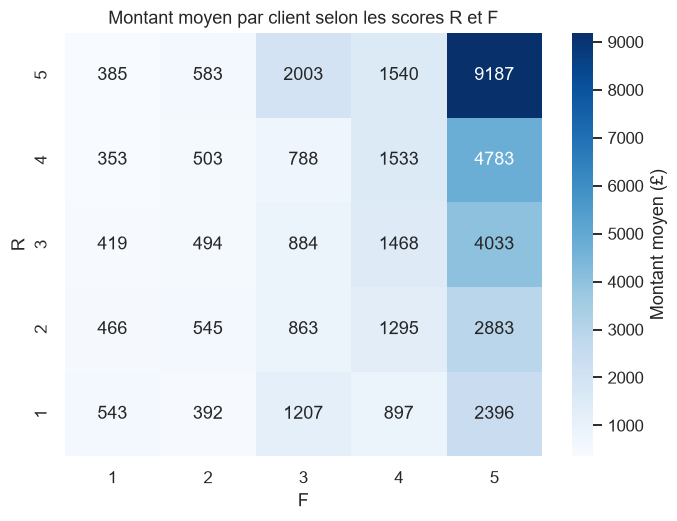

In [9]:
carte = rfm.pivot_table(index="R", columns="F", values="Montant", aggfunc="mean").sort_index(ascending=False)
plt.figure(figsize=(7, 5))
sns.heatmap(carte, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "Montant moyen (£)"})
plt.title("Montant moyen par client selon les scores R et F")
plt.savefig(OUTPUT + "heatmap_rf_montant.png", bbox_inches="tight")
plt.show()

## 5. Résultats clés

In [10]:
def part(seg, col):
    return resume.loc[seg, col] if seg in resume.index else 0.0

segment_principal = resume["Clients"].idxmax()
print(f"Segment le plus nombreux : {segment_principal} ({part(segment_principal, '% clients'):.1f} % des clients)")
print(f"Champions : {part('Champions', '% clients'):.1f} % des clients pour {part('Champions', '% CA'):.1f} % du CA")
print(f"Loyal Customers : {part('Loyal Customers', '% clients'):.1f} % des clients pour {part('Loyal Customers', '% CA'):.1f} % du CA")
a_risque = part("At Risk", "% clients") + part("Can't Lose Them", "% clients")
ca_risque = part("At Risk", "% CA") + part("Can't Lose Them", "% CA")
print(f"Clients à risque (At Risk + Can't Lose Them) : {a_risque:.1f} % des clients, {ca_risque:.1f} % du CA")

Segment le plus nombreux : Hibernating (24.6 % des clients)
Champions : 14.6 % des clients pour 48.7 % du CA
Loyal Customers : 19.1 % des clients pour 26.5 % du CA
Clients à risque (At Risk + Can't Lose Them) : 14.8 % des clients, 9.0 % du CA


## 6. Recommandations marketing

| Segment | Profil | Action recommandée |
|---|---|---|
| **Champions** | Achètent souvent, récemment, et dépensent le plus | Programme VIP, accès en avant-première, demande d'avis et de parrainage |
| **Loyal Customers** | Clients réguliers | Offres de fidélité, ventes croisées sur les catégories complémentaires |
| **Potential Loyalists / Promising** | Clients récents à fort potentiel | Séquence d'e-mails de bienvenue, recommandations personnalisées |
| **At Risk / Can't Lose Them** | Anciens bons clients qui n'achètent plus | **Campagne de réactivation prioritaire** : offre personnalisée, prise de contact directe pour les plus gros |
| **About to Sleep / Need Attention** | Activité en baisse | Relance avec une offre limitée dans le temps |
| **Hibernating** | Peu actifs et peu récents | Campagnes à faible coût, ou exclusion pour réduire les coûts d'envoi |

**À retenir :** une petite partie des clients génère l'essentiel du chiffre d'affaires. Protéger les segments **Champions** et **Loyal Customers**, et réactiver rapidement les clients **At Risk**, a un impact bien plus fort qu'une campagne identique envoyée à toute la base.

In [11]:
rfm.reset_index().to_csv(OUTPUT + "rfm_segments.csv", index=False)
print("Export : output/rfm_segments.csv")

Export : output/rfm_segments.csv
